🤖 Initializing Machine Learning Valuation Engine...
✂️ Sampling 150,000 rows for fast training...
⏳ Training Random Forest model... (this will take 10-15 seconds)
✅ Model Trained. MAE: 3459.02 AED/sqm | R-squared: 0.64
🔍 Scanning transactions for undervalued deals...

--- 🚨 TOP 15 UNDERVALUED DEALS IN DUBAI (Sold >20% below AI valuation) ---


,instance_date,area_name_en,building_name,rooms_bucket,property_type_label,price_aed,price_per_sqm,expected_psm,discount_pct
1092383,2026-10-26,Al Merkadh,None,NaN,Unit,600000,3383.903897,21924.580188,84.565707
1001456,2026-02-11,Business Bay,Capital Bay B,0.0,Unit,201600,3496.964441,22482.202456,84.445632
1000769,2026-02-10,Business Bay,Capital Bay B,2.0,Unit,360000,3150.984683,19924.312555,84.185228
508324,2022-08-15,Burj Khalifa,Imperial Avenue,5.0,Unit,10557792,7629.840650,42469.773339,82.034657
502448,2022-07-14,Burj Khalifa,Imperial Avenue,5.0,Unit,3917433,7629.926183,42469.773339,82.034455
502548,2022-07-14,Burj Khalifa,Imperial Avenue,5.0,Unit,3917433,7629.926183,42469.773339,82.034455
502544,2022-07-14,Burj Khalifa,Imperial Avenue,5.0,Unit,3917433,7629.926183,42469.773339,82.034455
502542,2022-07-14,Burj Khalifa,Imperial Avenue,5.0,Unit,3917433,7629.926183,42469.773339,82.034455
502541,2022-07-14,Burj Khalifa,Imperial Avenue,5.0,Unit,4146255,7629.927128,42469.773339,82.034453
502549,2022-07-14,Burj Khalifa,Imperial Avenue,5.0,Unit,4146255,7629.927128,42469.773339,82.034453


📊 Extracting feature importances...


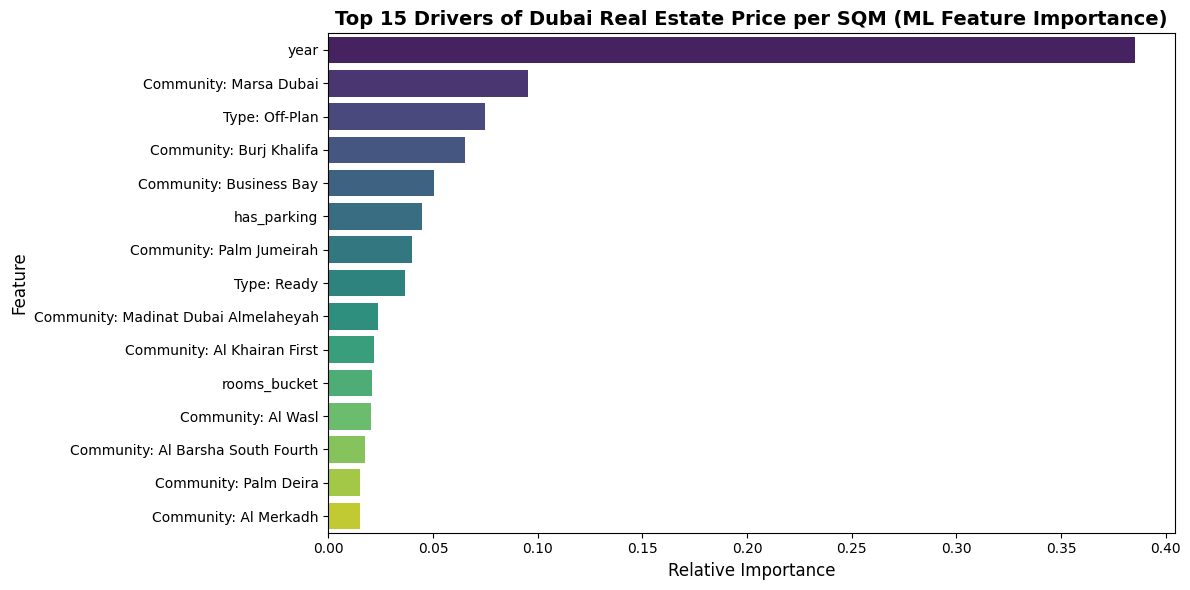

📊 Chart saved to E:\DataAnalytics\Projects\Dubai_Real_Estate_Analytics\visualizations\fig05_ml_feature_importance.png


In [2]:
import sys
sys.path.append('../')
import pandas as pd
import warnings
warnings.filterwarnings('ignore') 

import importlib
import src.models
importlib.reload(src.models)

from src.models import train_and_find_undervalued, plot_feature_importance

# 1. Load Data
df = pd.read_parquet('../data/processed/clean_transactions.parquet')

# 2. Train Model and Find Deals (Expecting 4 variables)
top_deals, mae, r2, trained_model = train_and_find_undervalued(df)

# 3. Show the Top Deals
print("\n--- 🚨 TOP 15 UNDERVALUED DEALS IN DUBAI (Sold >20% below AI valuation) ---")
display(top_deals)

# 4. Plot the AI's Brain (Feature Importance)
plot_feature_importance(trained_model)

In [4]:
# 1. Filter the original data for sanity (same filters as the model)
real_df = df[(df['area_sqm'] >= 30) & (df['price_aed'] >= 200000) & (df['price_per_sqm'] >= 3000)].copy()

# 2. Use the already-trained model to predict fair value
features = ['area_name_en', 'property_type_label', 'rooms_bucket', 'has_parking', 'reg_type_label', 'year']
real_df['expected_psm'] = trained_model.predict(real_df[features])

# 3. Calculate the discount
real_df['discount_pct'] = ((real_df['expected_psm'] - real_df['price_per_sqm']) / real_df['expected_psm']) * 100

# 4. Find REAL undervalued deals (15% to 35% discount, real rooms, real buildings)
top_real_deals = real_df[
    (real_df['discount_pct'] >= 15) & 
    (real_df['discount_pct'] <= 35) & 
    (real_df['rooms_bucket'] >= 1.0) & 
    (real_df['building_name'].notna())
].sort_values(by='discount_pct', ascending=False).head(15)

# 5. Show the results
print("\n--- 💎 TRUE UNDERVALUED DEALS (15% - 35% Discount) ---")
display(top_real_deals[['instance_date', 'area_name_en', 'building_name', 'rooms_bucket', 'price_aed', 'price_per_sqm', 'expected_psm', 'discount_pct']])


--- 💎 TRUE UNDERVALUED DEALS (15% - 35% Discount) ---


,instance_date,area_name_en,building_name,rooms_bucket,price_aed,price_per_sqm,expected_psm,discount_pct
274468,2015-12-21,Al Hebiah Fourth,Royale Residence 1,1.0,544661,6263.350966,9635.862877,34.999584
249642,2015-02-26,Dubai Investment Park First,Terrace Apartment 2,4.0,2900000,6263.363642,9635.862877,34.999452
438468,2021-05-27,Marsa Dubai,Ocean Heights,1.0,980000,10027.627136,15426.882457,34.999005
112354,2011-03-08,Al Thanyah Fifth,Concorde Tower 1,1.0,448491,6167.367987,9488.104621,34.998946
425505,2021-01-27,Business Bay,Elite Business Bay Residence,1.0,830000,9853.971269,15159.665649,34.998756
460866,2021-11-04,Al Hebiah Fourth,Venetian,2.0,835000,6240.191316,9600.084690,34.998581
512591,2022-08-31,Jabal Ali First,Gemz By Danube,2.0,1300000,12139.322066,18675.449136,34.998500
572019,2023-04-19,Jabal Ali First,Gemz By Danube,2.0,1300000,12139.322066,18675.449136,34.998500
135043,2012-04-02,Marsa Dubai,Murjan 3,3.0,1800000,7249.003262,11152.036838,34.998392
384982,2019-09-03,Marsa Dubai,Murjan 5,3.0,1650000,9435.580717,14515.837601,34.998028


In [5]:
# Clean up the display for the portfolio
final_display = top_real_deals[['instance_date', 'area_name_en', 'building_name', 'rooms_bucket', 'price_aed', 'price_per_sqm', 'expected_psm', 'discount_pct']].copy()

# Format the columns
final_display['instance_date'] = pd.to_datetime(final_display['instance_date']).dt.date
final_display['rooms_bucket'] = final_display['rooms_bucket'].astype(int)
final_display['price_aed'] = final_display['price_aed'].apply(lambda x: f"{x:,.0f}")
final_display['price_per_sqm'] = final_display['price_per_sqm'].apply(lambda x: f"{x:,.0f}")
final_display['expected_psm'] = final_display['expected_psm'].apply(lambda x: f"{x:,.0f}")
final_display['discount_pct'] = final_display['discount_pct'].apply(lambda x: f"{x:.1f}%")

display(final_display.style.hide(axis='index'))

instance_date,area_name_en,building_name,rooms_bucket,price_aed,price_per_sqm,expected_psm,discount_pct
2015-12-21,Al Hebiah Fourth,Royale Residence 1,1,"544,661","6,263","9,636",35.0%
2015-02-26,Dubai Investment Park First,Terrace Apartment 2,4,"2,900,000","6,263","9,636",35.0%
2021-05-27,Marsa Dubai,Ocean Heights,1,"980,000","10,028","15,427",35.0%
2011-03-08,Al Thanyah Fifth,Concorde Tower 1,1,"448,491","6,167","9,488",35.0%
2021-01-27,Business Bay,Elite Business Bay Residence,1,"830,000","9,854","15,160",35.0%
2021-11-04,Al Hebiah Fourth,Venetian,2,"835,000","6,240","9,600",35.0%
2022-08-31,Jabal Ali First,Gemz By Danube,2,"1,300,000","12,139","18,675",35.0%
2023-04-19,Jabal Ali First,Gemz By Danube,2,"1,300,000","12,139","18,675",35.0%
2012-04-02,Marsa Dubai,Murjan 3,3,"1,800,000","7,249","11,152",35.0%
2019-09-03,Marsa Dubai,Murjan 5,3,"1,650,000","9,436","14,516",35.0%
